In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from pathlib import Path
import math
from scipy.interpolate import CubicSpline 



In [ ]:
# Plotting setup

from my_plot import set_size
import seaborn as sns
width =  508.0
widthcol = 244
plt.rcParams['font.size']=12

colors1=sns.color_palette("rocket",4) #personal fav 
colors2=sns.color_palette("mako",4) #also nice
colors3 = plt.colormaps['Spectral'].resampled(4)

colors4 = ['#c3121e', '#0348a1', '#ffb01c', '#027608', '#0193b0', '#9c5300', '#949c01', '#7104b5']
#            0sangre,   1neptune,  2pumpkin,  3clover,   4denim,    5cocoa,    6cumin,    7berry


#%matplotlib widget

In [4]:
# Function to format numbers in scientific notation for plots

f =  ScalarFormatter(useOffset=False, useMathText=True)
f.set_scientific(True)
f.set_powerlimits((0, 0))

def sci_notation(x):
    if x == 0:
        return "0"
    else:
        formatted = f"{x:.2e}"  # Converte in notazione scientifica
        coefficient, exponent = formatted.split('e')
        exponent = int(exponent)  # Converti l'esponente a intero
        return f"${coefficient} \\times 10^{{{exponent}}}$"  # Notazione LaTeX

In [5]:
# Initalizing constants

K = 1.380649e-23 # J / K
vc = 299792458 # m / s
h_pl = 6.62607015e-34 # J*s
T_cmb = 2.726 # K
omegab_h2 = 0.0224

I0 =(2*K**3*T_cmb**3)/(vc**2*h_pl**2)*1e26 # in Jy / sr
print(I0/1e6, "MJy sr^-1")

270.2115654196308 MJy sr^-1


In [6]:
# Normalised distortion spectral shapes

def nbb(x): return (1/(np.exp(x)-1)) # * I0
def G(x): return (x * np.exp(x) * nbb(x)**2 )   # intensity not occupation number /4.0 * I0
def Y(x): return x**3 * I0 * (G(x) * ( x * ( 2 * nbb(x) + 1 ) - 4 ) ) / 4.0
def M(x): return x**3 * I0 * (G(x) * ( 1.0 / 2.1923 - 1.0 / x ) ) * 1.401
def D(x): return x**3 * I0 * (G(x) * 1.6449 / (3*2.4041) - nbb(x) / x) / 0.5421 

In [7]:
def extract_Ix_from_files(folder_path, pattern="Dn_final.photon_conversion.dark-photon.dat"):
    """Extract x and Ix data from files in a folder, regular heating mode wiith no batch"""
    folder = Path(folder_path) / "PDE-non-linear"
    file_path = next(folder.glob(pattern))
    
    x = []
    Ix = []
    
    data = np.loadtxt(file_path, comments='#')  
    x.extend(data[:, 0])   # All x values from column 0
    Ix.extend(data[:, 5])  # All Ix values from column 5

    return np.array(x), np.array(Ix)

In [8]:
def extract_Ix_from_files_FH(folder_path, pattern="full_spectrum.dat_ymax15_y_bg.dat"):
    """Extract x and Ix data from files in a folder, FH module"""
    folder = Path(folder_path) / "FH" 
    file_path = next(folder.glob(pattern))
    
    x = []
    Ix = []
  
    data = np.loadtxt(file_path, comments='#')
    x.extend(data[:, 0])   # All x values from column 0
    Ix.extend(data[:, 1])  # All Ix values from column 5
    
    return np.array(x), np.array(Ix)

In [ ]:
x_spec , Ix_spec = extract_Ix_from_files_FH("../Data/","Dx.dat") 

spline_Ix_spec = CubicSpline(x_spec, Ix_spec)

In [ ]:
# Extract data from simulation files
x , Ix = extract_Ix_from_files("../Data/Test-code-ze8e3/Photon-conversion/") # [I] = Jy / sr
x_FH , Ix_FH = extract_Ix_from_files("../Data/Test-code-ze8e3/Photon-conversion/") # [I] = Jy / sr

# Find common frequency range
xmin = max(x.min(), x_FH.min(), 1e-3)
xmax = min(x.max(), x_FH.max())

# Mask arrays to common range
mask_x = (x >= xmin) & (x <= xmax)
mask_x_FH = (x_FH >= xmin) & (x_FH <= xmax)

x_common = np.linspace(xmin, xmax, 500)

# Cubic spline fits (exact interpolation for clean simulation data)
spline_Ix = CubicSpline(x[mask_x], Ix[mask_x])
spline_Ix_FH = CubicSpline(x_FH[mask_x_FH], Ix_FH[mask_x_FH])


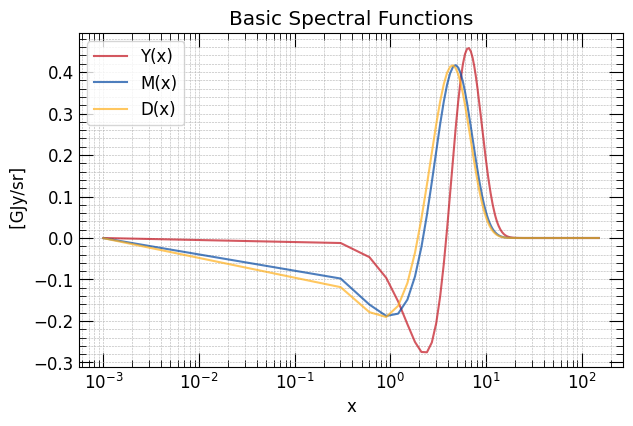

In [11]:
# Plot Analytical Spectra
fig, ax1 = plt.subplots(1, 1, figsize=set_size(width))

ax1.plot(x_common, Y(x_common) / 1e9, label="Y(x)", color=colors4[0], alpha=0.7, linestyle="-")
ax1.plot(x_common, M(x_common) / 1e9, label="M(x)", color=colors4[1], alpha=0.7, linestyle="-")
ax1.plot(x_common, D(x_common) / 1e9, label="D(x)", color=colors4[2], alpha=0.7, linestyle="-")


ax1.set_xscale('log')
#ax1.set_yscale('log')
#ax1.set_ylim(top=6)
#ax1.set_xlim([1e+0, 5e+3])

plt.minorticks_on()
plt.tick_params(direction='in',right=True, top=True)
plt.tick_params(labelsize=12)
plt.tick_params(labelbottom=True, labeltop=False, labelright=False, labelleft=True)
plt.tick_params(direction='in',which='minor', length=5, bottom=True, top=True, left=True, right=True)
plt.tick_params(direction='in',which='major', length=10, bottom=True, top=True, left=True, right=True)

ax1.set_ylabel(" [GJy/sr]")
ax1.set_xlabel("x")
ax1.set_title("Basic Spectral Functions")
ax1.grid(True, which='both', linestyle='--', linewidth=0.4)
plt.legend(loc='upper left')
#plt.savefig('outputs/H0_evolution.pdf', dpi=300, bbox_inches="tight")
plt.show()

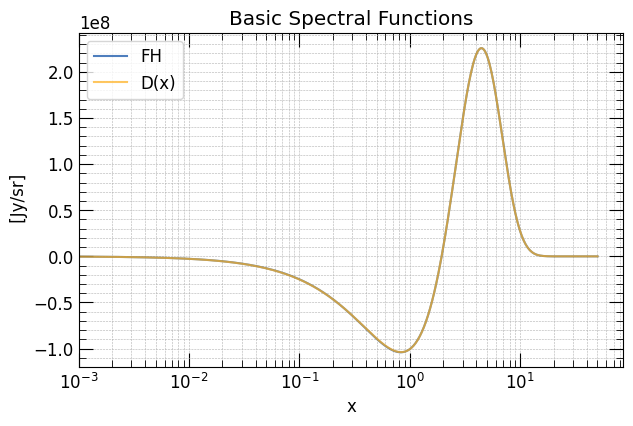

In [12]:

# Plot Analytical Spectra
gamma = 246.254
fig, ax1 = plt.subplots(1, 1, figsize=set_size(width))

#ax1.plot(x_common, spline_Ix(x_common), label="Heating mode 10", color=colors4[0], alpha=0.7, linestyle="-")
ax1.plot(x_spec, spline_Ix_spec(x_spec)*I0, label="FH", color=colors4[1], alpha=0.7, linestyle="-")
ax1.plot(x_spec, 0.5421 * D(x_spec) , label="D(x)", color=colors4[2], alpha=0.7, linestyle="-")


ax1.set_xscale('log')
#ax1.set_yscale('log')
#ax1.set_ylim(top=6)
ax1.set_xlim(left=1e-3)

plt.minorticks_on()
plt.tick_params(direction='in',right=True, top=True)
plt.tick_params(labelsize=12)
plt.tick_params(labelbottom=True, labeltop=False, labelright=False, labelleft=True)
plt.tick_params(direction='in',which='minor', length=5, bottom=True, top=True, left=True, right=True)
plt.tick_params(direction='in',which='major', length=10, bottom=True, top=True, left=True, right=True)

ax1.set_ylabel(" [Jy/sr]")
ax1.set_xlabel("x")
ax1.set_title("Basic Spectral Functions")
ax1.grid(True, which='both', linestyle='--', linewidth=0.4)
plt.legend(loc='upper left')
#plt.savefig('outputs/H0_evolution.pdf', dpi=300, bbox_inches="tight")
plt.show()

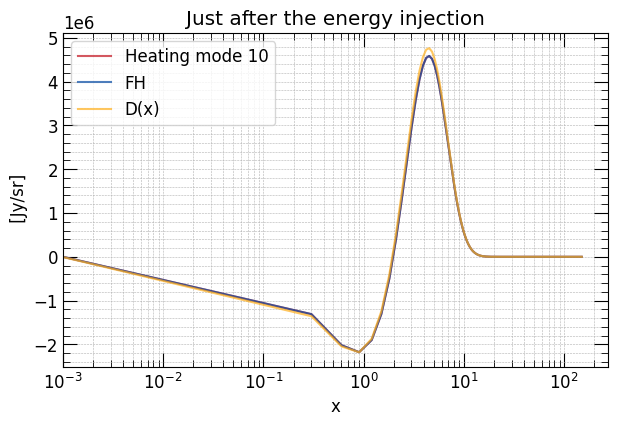

In [13]:

# Plot Analytical Spectra
gamma = 0.0211189
fig, ax1 = plt.subplots(1, 1, figsize=set_size(width))

ax1.plot(x_common, spline_Ix(x_common), label="Heating mode 10", color=colors4[0], alpha=0.7, linestyle="-")
ax1.plot(x_common, spline_Ix_FH(x_common), label="FH", color=colors4[1], alpha=0.7, linestyle="-")
ax1.plot(x_common, 0.5421 * D(x_common) * gamma, label="D(x)", color=colors4[2], alpha=0.7, linestyle="-")


ax1.set_xscale('log')
#ax1.set_yscale('log')
#ax1.set_ylim(top=6)
ax1.set_xlim(left=1e-3)

plt.minorticks_on()
plt.tick_params(direction='in',right=True, top=True)
plt.tick_params(labelsize=12)
plt.tick_params(labelbottom=True, labeltop=False, labelright=False, labelleft=True)
plt.tick_params(direction='in',which='minor', length=5, bottom=True, top=True, left=True, right=True)
plt.tick_params(direction='in',which='major', length=10, bottom=True, top=True, left=True, right=True)

ax1.set_ylabel(" [Jy/sr]")
ax1.set_xlabel("x")
ax1.set_title("Just after the energy injection")
ax1.grid(True, which='both', linestyle='--', linewidth=0.4)
plt.legend(loc='upper left')
#plt.savefig('outputs/H0_evolution.pdf', dpi=300, bbox_inches="tight")
plt.show()

In [14]:
# Extract data from simulation files
x2 , Ix2 = extract_Ix_from_files("../Data/Test-code-zcon1e4/Photon-conversion/") # [I] = Jy / sr
x_FH2 , Ix_FH2 = extract_Ix_from_files("../Data/Test-code-zcon1e4/Photon-conversion/") # [I] = Jy / sr

# Find common frequency range
xmin2 = max(x2.min(), x_FH2.min(), 1e-3)
xmax2 = min(x2.max(), x_FH2.max())

# Mask arrays to common range
mask_x2 = (x2 >= xmin2) & (x2 <= xmax2)
mask_x_FH2 = (x_FH2 >= xmin2) & (x_FH2 <= xmax2)

x_common2 = np.linspace(xmin2, xmax2, 500)

# Cubic spline fits (exact interpolation for clean simulation data)
spline_Ix2 = CubicSpline(x2[mask_x2], Ix2[mask_x2])
spline_Ix_FH2 = CubicSpline(x_FH2[mask_x_FH2], Ix_FH2[mask_x_FH2])

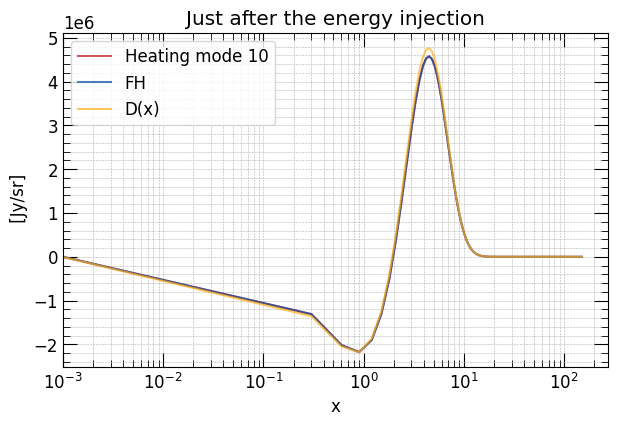

In [15]:

# Plot Analytical Spectra
gamma = 0.0211189
fig, ax1 = plt.subplots(1, 1, figsize=set_size(width))

ax1.plot(x_common2, spline_Ix2(x_common2), label="Heating mode 10", color=colors4[0], alpha=0.7, linestyle="-")
ax1.plot(x_common2, spline_Ix_FH2(x_common2), label="FH", color=colors4[1], alpha=0.7, linestyle="-")
ax1.plot(x_common2, 0.5421 * D(x_common2) * gamma, label="D(x)", color=colors4[2], alpha=0.7, linestyle="-")


ax1.set_xscale('log')
#ax1.set_yscale('log')
#ax1.set_ylim(top=6)
ax1.set_xlim(left=1e-3)

plt.minorticks_on()
plt.tick_params(direction='in',right=True, top=True)
plt.tick_params(labelsize=12)
plt.tick_params(labelbottom=True, labeltop=False, labelright=False, labelleft=True)
plt.tick_params(direction='in',which='minor', length=5, bottom=True, top=True, left=True, right=True)
plt.tick_params(direction='in',which='major', length=10, bottom=True, top=True, left=True, right=True)

ax1.set_ylabel(" [Jy/sr]")
ax1.set_xlabel("x")
ax1.set_title("Just after the energy injection")
ax1.grid(True, which='both', linestyle='--', linewidth=0.4)
plt.legend(loc='upper left')
#plt.savefig('outputs/H0_evolution.pdf', dpi=300, bbox_inches="tight")
plt.show()